# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA y evaluación de mejoras al modelo (Semana 14)

- Profesor: Elias Buitrago Bolivar  
- Estudiante: Carlos Alberto Mancilla Valle
- Universidad Central  
- Caso: Brazilian E-Commerce Public Dataset by Olist

### Objetivo

Evaluar el impacto de la reducción de dimensionalidad mediante Análisis de Componentes Principales (PCA) y de diferentes niveles de regularización L2 sobre un modelo de regresión logística destinado a predecir entregas tardías en pedidos de Olist.

Para ello, se compararán cuatro configuraciones del modelo utilizando métricas de clasificación y costos empresariales asociados a los errores de predicción. Adicionalmente, se aplicará la prueba estadística de Kolmogorov-Smirnov (KS) para analizar la distribución del valor del flete entre los conjuntos de entrenamiento y validación.

### Alcance

El laboratorio reutiliza la preparación de datos de la Semana 12 e incorpora experimentos de reducción de dimensionalidad, regularización y evaluación estadística, manteniendo la reproducibilidad y evitando fugas de información entre los conjuntos de datos.

### Configuración del entorno local (`src/iniciarEntorno`)

Esta sección permite preparar y verificar las dependencias necesarias para ejecutar el laboratorio en un entorno local, como Visual Studio Code o Jupyter Notebook.

> **Consideraciones de ejecución:**
>
> - **Entorno local:** antes de ejecutar esta celda, se debe crear y activar el entorno virtual (`venv`) y seleccionarlo como kernel del notebook, siguiendo las instrucciones de `notebooks/README.md`.
> - **Google Colab:** esta configuración es opcional y puede omitirse si las dependencias necesarias ya están disponibles.
> - **Gestión de dependencias:** se utiliza el módulo `src/iniciarEntorno/gestor_dependencias.py` para verificar e instalar las bibliotecas declaradas en `requirements.txt`.
> - **Reproducibilidad:** se recomienda utilizar las versiones de las dependencias definidas para el proyecto, con el fin de mantener un entorno de ejecución consistente.


In [1]:
import sys
from pathlib import Path

# Detectar la raíz del proyecto buscando hacia arriba la carpeta que contiene 'src'
raiz = Path.cwd()
while raiz.name and not (raiz / 'src').exists():
    if raiz.parent == raiz:  # Llegó al directorio raíz del sistema sin encontrar src
        break
    raiz = raiz.parent

if not (raiz / "src").is_dir():
    raise FileNotFoundError(
        "No se encontró la carpeta 'src'. "
        "Ejecuta el notebook dentro del repositorio del proyecto."
    )

# Añadir la raíz del proyecto al sys.path
if str(raiz) not in sys.path:
    sys.path.append(str(raiz))

# Importación desde el módulo src.iniciarEntorno
from src.iniciarEntorno.gestor_dependencias import preparar_entorno

preparar_entorno()

    [Iniciando Entorno] Raíz detectada: C:\Users\yhonny\Desktop\Proyectos\data-analytics-ml-challenge
    [Entorno Listo] Todas las dependencias están al día


## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [2]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)
from sklearn.decomposition import PCA
from sklearn.base import clone
from scipy.stats import ks_2samp

print("Importaciones cargadas con éxito")

Importaciones cargadas con éxito


In [3]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [4]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [5]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [6]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [7]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [8]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 19
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 19 | Semilla: 1019
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 120d6b36c5fa


## 3. Preparación del preprocesamiento

Se define un preprocesamiento común para los modelos de clasificación, compuesto por dos rutas:

- **Variables numéricas:** imputación de valores faltantes mediante la mediana y estandarización con `StandardScaler`.
- **Variables categóricas:** imputación mediante la moda y codificación con `OneHotEncoder`.

Las transformaciones se ajustarán exclusivamente con los datos de entrenamiento mediante `Pipeline`, evitando fugas de información hacia los conjuntos de validación y prueba.

Este preprocesamiento se utilizará como referencia para construir las configuraciones con y sin reducción de dimensionalidad mediante PCA.


In [9]:
# Configuración del preprocesamiento según el tipo de variable
preprocesamiento = ColumnTransformer([
    # Variables numéricas:
    # Reemplaza los valores faltantes por la mediana de cada columna.
    # Estandariza los valores para que tengan media 0 y desviación estándar 1.
    ('numericas', make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler()
    ), columnas_numericas),

    # Variables categóricas:
    # Reemplaza los valores faltantes por la categoría más frecuente.
    # Convierte las categorías en columnas binarias mediante One-Hot Encoding.
    # Ignora categorías desconocidas al transformar nuevos datos.
    ('categoricas', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), columnas_categoricas)
])

# Resumen de las variables utilizadas en el preprocesamiento
print('Variables numéricas:', len(columnas_numericas))
print('Variables categóricas:', len(columnas_categoricas))
print('Total de variables:', len(columnas_numericas) + len(columnas_categoricas))
print('Preprocesamiento configurado correctamente.')


Variables numéricas: 24
Variables categóricas: 4
Total de variables: 28
Preprocesamiento configurado correctamente.



## 4. Actividad 1 - Reducción de dimensionalidad mediante PCA

En esta actividad se aplica el Análisis de Componentes Principales (PCA) sobre las variables numéricas del conjunto de datos Olist, con el propósito de reducir su dimensionalidad conservando al menos el 90 % de la varianza acumulada.

Antes de aplicar PCA, las variables numéricas se imputan mediante la mediana y se estandarizan con `StandardScaler`. Las variables categóricas se mantienen fuera de PCA y se procesan mediante One-Hot Encoding.

El ajuste de las transformaciones se realiza exclusivamente con los datos de entrenamiento para evitar fugas de información.

Se analizará la cantidad de componentes principales necesarias y el porcentaje de varianza explicado.

In [10]:
# Actividad 1 - PCA con 90 % de varianza explicada

# Configuración del pipeline de reducción de dimensionalidad
pipeline_pca = make_pipeline(
    # Reemplaza los valores faltantes por la mediana de cada variable numérica.
    SimpleImputer(strategy='median'),

    # Estandariza las variables para evitar que sus escalas dominen el PCA.
    StandardScaler(),

    # Selecciona el mínimo número de componentes que explique al menos el 90 %
    # de la varianza. El solver 'full' realiza la descomposición SVD completa.
    PCA(n_components=0.90, svd_solver='full')
)

# Ajusta las transformaciones únicamente con las variables numéricas
# de entrenamiento y obtiene su representación en componentes principales.
X_train_pca = pipeline_pca.fit_transform(
    X_train[columnas_numericas]
)

# Recupera el objeto PCA ya ajustado para consultar sus resultados.
pca = pipeline_pca.named_steps['pca']

# Resumen de la reducción de dimensionalidad
print('Variables numéricas originales:', len(columnas_numericas))
print('Componentes principales:', pca.n_components_)
print('Varianza explicada acumulada:',
      round(pca.explained_variance_ratio_.sum() * 100, 2), '%')
print('Dimensiones transformadas:', X_train_pca.shape)


Variables numéricas originales: 24
Componentes principales: 15
Varianza explicada acumulada: 90.62 %
Dimensiones transformadas: (24500, 15)


### 4.1. Curva de varianza explicada acumulada

Se representa gráficamente la varianza acumulada por los componentes principales para identificar cuántos son necesarios para conservar al menos el 90 % de la información estadística de las variables numéricas.


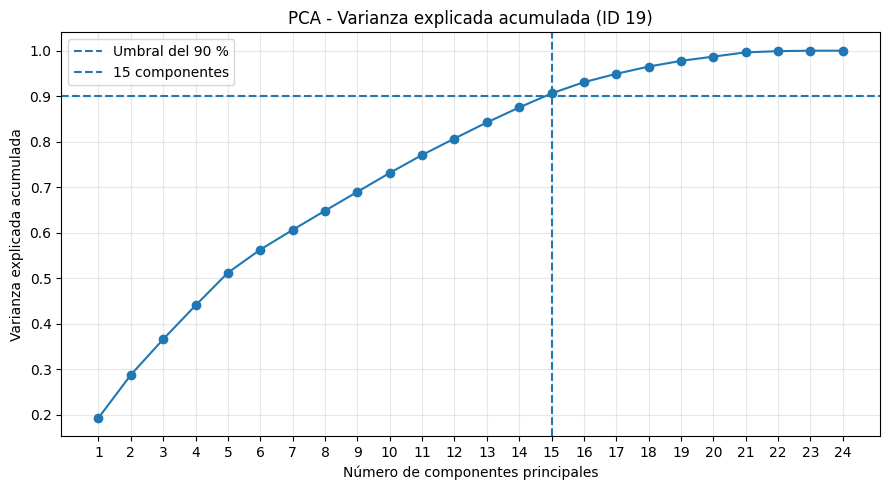

In [11]:
# PCA completo para visualizar la varianza explicada acumulada
pca_completo = make_pipeline(
    # Completa los valores faltantes con la mediana de cada variable.
    SimpleImputer(strategy='median'),

    # Estandariza las variables antes de aplicar PCA.
    StandardScaler(),

    # Conserva todos los componentes para analizar su aporte individual.
    PCA()
)

# Ajusta el pipeline exclusivamente con los datos de entrenamiento.
pca_completo.fit(X_train[columnas_numericas])

# Calcula la suma acumulada de la varianza explicada por cada componente.
# np.cumsum() permite observar cuánta varianza se conserva al añadir componentes.
varianza_acumulada = np.cumsum(
    pca_completo.named_steps['pca'].explained_variance_ratio_
)

# Genera una secuencia desde 1 hasta el número total de componentes.
# Cada número representa la cantidad de componentes utilizados.
componentes = np.arange(1, len(varianza_acumulada) + 1)

# Construcción de la curva de varianza explicada acumulada
plt.figure(figsize=(9, 5))

# Representa la varianza acumulada según el número de componentes.
plt.plot(componentes, varianza_acumulada, marker='o')

# Marca el umbral mínimo del 90 % de varianza explicada.
plt.axhline(0.90, linestyle='--', label='Umbral del 90 %')

# Señala el número de componentes seleccionado en la Actividad 1.
plt.axvline(
    pca.n_components_,
    linestyle='--',
    label=f'{pca.n_components_} componentes'
)

# Configuración de títulos, ejes y elementos visuales
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA - Varianza explicada acumulada (ID 19)')
plt.xticks(componentes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Actividad 2 - Comparación de modelos de clasificación

En esta actividad se comparan cuatro configuraciones de regresión logística para evaluar el impacto de PCA y de la regularización L2 sobre la predicción de entregas tardías.

Los experimentos se definen de la siguiente manera:

- **Modelo A:** variables numéricas sin PCA, con `C=1.0`.
- **Modelo B:** variables numéricas con PCA al 90 % de varianza, con `C=1.0`.
- **Modelo C:** variables numéricas con PCA al 90 % de varianza, con `C=0.1`.
- **Modelo D:** variables numéricas con PCA al 90 % de varianza, con `C=10.0`.

Todos los modelos utilizan `class_weight='balanced'` y un umbral de clasificación de 0.50.

La comparación se realizará sobre el conjunto de validación mediante Accuracy, Precision, Recall, F1, Average Precision (AP), falsos positivos, falsos negativos y costos empresariales asociados a los errores de predicción.

El conjunto de prueba final permanecerá reservado y no se utilizará para seleccionar el mejor modelo.


In [12]:
# Actividad 2 - Configuración de preprocesamientos

# Reutiliza el preprocesamiento original, que no incluye PCA.
preprocesamiento_sin_pca = preprocesamiento

# Configura un segundo preprocesamiento que incorpora PCA
# exclusivamente sobre las variables numéricas.
preprocesamiento_con_pca = ColumnTransformer([
    ('numericas', make_pipeline(
        # Completa los valores faltantes con la mediana de cada variable.
        SimpleImputer(strategy='median'),

        # Estandariza las variables antes de aplicar PCA.
        StandardScaler(),

        # Conserva el mínimo de componentes que explica al menos el 90 %
        # de la varianza numérica mediante descomposición SVD completa.
        PCA(n_components=0.90, svd_solver='full')
    ), columnas_numericas),

    ('categoricas', make_pipeline(
        # Completa los valores faltantes con la categoría más frecuente.
        SimpleImputer(strategy='most_frequent'),

        # Convierte las categorías en variables binarias e ignora
        # categorías desconocidas durante la transformación.
        OneHotEncoder(handle_unknown='ignore')
    ), columnas_categoricas)
])

# Confirmación de las configuraciones disponibles
print('Preprocesamiento sin PCA: configurado')
print('Preprocesamiento con PCA: configurado')
print('Varianza mínima requerida: 90 %')


Preprocesamiento sin PCA: configurado
Preprocesamiento con PCA: configurado
Varianza mínima requerida: 90 %


In [13]:
# Actividad 2 - Entrenamiento de los cuatro modelos

# Define las configuraciones de preprocesamiento y regularización.
# A: sin PCA; B, C y D: con PCA y diferentes valores de C.
configuraciones = {
    'A': (preprocesamiento_sin_pca, 1.0),
    'B': (preprocesamiento_con_pca, 1.0),
    'C': (preprocesamiento_con_pca, 0.1),
    'D': (preprocesamiento_con_pca, 10.0)
}

# Almacena los modelos entrenados para su posterior evaluación.
modelos = {}

# Recorre cada configuración y construye un pipeline independiente.
for nombre, (procesamiento, c) in configuraciones.items():
    modelo = make_pipeline(
        # Crea una copia independiente del preprocesamiento para evitar
        # compartir parámetros ajustados entre los distintos modelos.
        clone(procesamiento),

        LogisticRegression(
            # Controla la regularización: valores menores implican
            # una penalización más intensa sobre los coeficientes.
            C=c,

            # Ajusta automáticamente los pesos de las clases para
            # compensar su desbalance en el conjunto de entrenamiento.
            class_weight='balanced',

            # Establece un máximo de 2000 iteraciones para la optimización.
            max_iter=2000,

            # Fija la semilla para favorecer la reproducibilidad.
            random_state=1019
        )
    )

    # Ajusta el preprocesamiento y entrena la regresión logística
    # utilizando exclusivamente los datos de entrenamiento.
    modelo.fit(X_train, y_train)

    # Guarda el pipeline entrenado utilizando su identificador.
    modelos[nombre] = modelo

    print(
        f'Modelo {nombre}: entrenado | C={c} | '
        f'PCA={"No" if nombre == "A" else "Sí"}'
    )


Modelo A: entrenado | C=1.0 | PCA=No
Modelo B: entrenado | C=1.0 | PCA=Sí
Modelo C: entrenado | C=0.1 | PCA=Sí
Modelo D: entrenado | C=10.0 | PCA=Sí


In [14]:
# Actividad 2 - Evaluación de los cuatro modelos

# Almacena las métricas y los costos obtenidos por cada modelo.
resultados = []

# Evalúa los modelos entrenados utilizando el conjunto de validación.
for nombre, modelo in modelos.items():

    # Genera las clases predichas (0: a tiempo, 1: entrega tardía).
    pred = modelo.predict(X_valid)

    # Obtiene la probabilidad estimada de la clase positiva (1).
    # [:, 1] selecciona la segunda columna de probabilidades.
    proba = modelo.predict_proba(X_valid)[:, 1]

    # Calcula la matriz de confusión y extrae sus cuatro resultados:
    # TN: verdaderos negativos; FP: falsos positivos;
    # FN: falsos negativos; TP: verdaderos positivos.
    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred, labels=[0, 1]
    ).ravel()

    # Registra las métricas de clasificación y el costo empresarial.
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_valid, pred),
        'Precision': precision_score(y_valid, pred, zero_division=0),
        'Recall': recall_score(y_valid, pred, zero_division=0),
        'F1': f1_score(y_valid, pred, zero_division=0),

        # AP evalúa la relación precisión-recall utilizando
        # las probabilidades, en lugar de las clases predichas.
        'AP': average_precision_score(y_valid, proba),

        'FP': fp,
        'FN': fn,

        # Penalización didáctica: 8 BRL por falsa alerta
        # y 35 BRL por entrega tardía no detectada.
        'Costo (BRL)': 8 * fp + 35 * fn
    })

# Convierte los resultados en una tabla e identifica cada fila por modelo.
comparacion = pd.DataFrame(resultados).set_index('Modelo')

# Presenta las métricas redondeadas a cuatro decimales.
print('Comparación de modelos en validación:\n')
print(comparacion.round(4).to_string())


Comparación de modelos en validación:

        Accuracy  Precision  Recall      F1      AP    FP   FN  Costo (BRL)
Modelo                                                                     
A         0.6547     0.1183  0.6366  0.1996  0.1402  1684  129        17987
B         0.6493     0.1110  0.5972  0.1872  0.1130  1698  143        18589
C         0.6484     0.1095  0.5887  0.1846  0.1138  1700  146        18710
D         0.6482     0.1111  0.6000  0.1874  0.1122  1705  142        18610


## 6. Actividad 3 - Prueba de Kolmogorov-Smirnov

Se aplica la prueba estadística de Kolmogorov-Smirnov (KS) de dos muestras para comparar las distribuciones de la variable `valor_flete` entre los conjuntos de entrenamiento y validación.

Se establecen las siguientes hipótesis:

- **H₀:** la variable `valor_flete` sigue la misma distribución poblacional en ambos conjuntos.
- **H₁:** las distribuciones poblacionales de `valor_flete` son diferentes.

Se utiliza un nivel de significancia de `α = 0.05`.

La prueba permite calcular el estadístico D y el valor p para determinar si existe evidencia estadística suficiente para rechazar la hipótesis nula.

Este análisis no evalúa directamente el rendimiento predictivo de los modelos.


In [15]:
# Actividad 3 - Prueba de Kolmogorov-Smirnov

# Extrae los valores de flete de entrenamiento y validación.
# dropna() elimina los valores faltantes para realizar la prueba.
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

# Compara las distribuciones de ambas muestras mediante la prueba KS.
# D mide la máxima diferencia entre sus distribuciones acumuladas
# empíricas; p permite evaluar la evidencia contra la hipótesis nula.
d, p = ks_2samp(flete_train, flete_valid)

# Presenta los resultados de la prueba estadística.
print('Estadístico KS (D):', round(d, 4))
print('Valor p:', round(p, 6))
print('Nivel de significancia:', 0.05)

# Contrasta el valor p con el nivel de significancia del 5 %.
# H0: ambas muestras proceden de la misma distribución.
# H1: las muestras proceden de distribuciones diferentes.
if p < 0.05:
    print('Conclusión: se rechaza H0.')
else:
    print('Conclusión: no se rechaza H0.')


Estadístico KS (D): 0.0092
Valor p: 0.852027
Nivel de significancia: 0.05
Conclusión: no se rechaza H0.


## 7. Interpretación general de resultados

### 7.1. Reducción de dimensionalidad

La aplicación del Análisis de Componentes Principales (PCA) permitió reducir las variables numéricas del conjunto de datos, conservando al menos el 90 % de la varianza acumulada.

| Indicador | Resultado |
|---|---:|
| Variables numéricas originales | 24 |
| Componentes principales seleccionados | 15 |
| Dimensiones eliminadas | 9 |
| Reducción de dimensionalidad | 37.50 % |
| Varianza explicada acumulada | 90.62 % |

La curva de varianza explicada acumulada, presentada en la sección 4.1, muestra cómo aumenta la proporción de varianza conservada a medida que se incorporan componentes principales.

El umbral mínimo del 90 % se alcanza con 15 componentes, que explican aproximadamente el 90.62 % de la varianza original. La intersección entre las líneas de referencia del gráfico confirma visualmente el número de componentes seleccionados.

A partir de este punto, la curva continúa aumentando, pero los componentes adicionales aportan incrementos progresivamente menores. Hacia los últimos componentes, la curva se aproxima al 100 % y presenta un comportamiento prácticamente horizontal, lo que indica una contribución marginal de las dimensiones restantes.

Este comportamiento evidencia que PCA logró sintetizar la información numérica en un menor número de dimensiones. La eliminación de 9 de las 24 dimensiones originales representa una reducción del 37.50 %, manteniendo la mayor parte de la variabilidad observada.

Sin embargo, conservar una proporción elevada de la varianza no garantiza preservar toda la información relevante para predecir entregas tardías. PCA identifica direcciones de máxima variabilidad, pero no necesariamente aquellas con mayor capacidad discriminativa respecto a la variable objetivo `is_late`.

Por esta razón, la utilidad de la reducción dimensional debe evaluarse mediante el rendimiento de los modelos de clasificación y no únicamente mediante la proporción de varianza conservada.

### 7.2. Comparación del rendimiento predictivo

Se evaluaron cuatro configuraciones de regresión logística sobre los 5.250 pedidos del conjunto de validación, utilizando un umbral de clasificación de 0.50 y ponderación de clases mediante `class_weight='balanced'`.

| Modelo | PCA | C | Accuracy | Precision | Recall | F1 | AP |
|---|---|---:|---:|---:|---:|---:|---:|
| A | No | 1.0 | 0.6547 | 0.1183 | 0.6366 | 0.1996 | 0.1402 |
| B | Sí | 1.0 | 0.6493 | 0.1110 | 0.5972 | 0.1872 | 0.1130 |
| C | Sí | 0.1 | 0.6484 | 0.1095 | 0.5887 | 0.1846 | 0.1138 |
| D | Sí | 10.0 | 0.6482 | 0.1111 | 0.6000 | 0.1874 | 0.1122 |

El modelo A, que conserva las variables numéricas originales sin aplicar PCA, obtuvo los mejores resultados en todas las métricas presentadas.

Su Recall de 0.6366 indica que identificó aproximadamente el 63.66 % de los pedidos que realmente llegaron tarde. Sin embargo, su Precision de 0.1183 muestra que solo alrededor del 11.83 % de las alertas emitidas correspondieron a retrasos reales.

Esta diferencia refleja la dificultad de clasificar una variable objetivo desbalanceada, donde los pedidos tardíos representan una proporción relativamente pequeña del conjunto de datos.

Al comparar los modelos A y B, que comparten el mismo valor de regularización (`C=1.0`), se observa que incorporar PCA disminuyó el rendimiento predictivo:

- El Recall pasó de 0.6366 a 0.5972.
- El F1 disminuyó de 0.1996 a 0.1872.
- El AP pasó de 0.1402 a 0.1130.

La disminución del AP es especialmente relevante porque indica una menor capacidad para concentrar pedidos realmente tardíos entre aquellos que reciben puntuaciones de riesgo más elevadas.

Estos resultados sugieren que algunas características originales contienen información útil para identificar retrasos que no se conserva completamente en la representación reducida mediante PCA.

Por lo tanto, aunque PCA logró reducir la dimensionalidad numérica, no produjo mejoras en el rendimiento predictivo de este experimento.

### 7.3. Efecto de la regularización

Se compararon los modelos B, C y D para analizar el impacto del parámetro `C`, manteniendo el mismo preprocesamiento con PCA.

En regresión logística, un valor menor de `C` representa una regularización más intensa, mientras que un valor mayor reduce la penalización aplicada a los coeficientes.

| Modelo | C | Intensidad de regularización | Recall | F1 |
|---|---:|---|---:|---:|
| B | 1.0 | Intermedia | 0.5972 | 0.1872 |
| C | 0.1 | Mayor | 0.5887 | 0.1846 |
| D | 10.0 | Menor | 0.6000 | 0.1874 |

El modelo C, con regularización más intensa, presentó el menor Recall y F1 entre las tres configuraciones que utilizan PCA.

Por su parte, el modelo D, con regularización más débil, obtuvo un Recall de 0.6000 y un F1 de 0.1874, ligeramente superiores a los resultados del modelo B.

Sin embargo, estas diferencias fueron pequeñas y ninguno de los modelos con PCA logró superar al modelo A.

Los resultados indican que modificar la intensidad de regularización produjo variaciones en el rendimiento, pero no permitió compensar la pérdida de capacidad predictiva observada al incorporar PCA.

En consecuencia, no se encontró evidencia de una mejora práctica relevante mediante los valores de `C` evaluados. Esto no significa que otros valores de regularización sean necesariamente inferiores, sino que las configuraciones analizadas no superaron la referencia sin PCA.

### 7.4. Impacto económico de los errores

Se calcularon los costos empresariales considerando una penalización didáctica de 8 BRL por falso positivo (FP) y 35 BRL por falso negativo (FN).

Un falso positivo corresponde a un pedido clasificado como tardío que realmente llegó a tiempo, mientras que un falso negativo representa un retraso real que el modelo no identificó.

El costo total se calculó mediante:

**Costo total = 8 × FP + 35 × FN**

| Modelo | FP | FN | Costo FP (BRL) | Costo FN (BRL) | Costo total (BRL) |
|---|---:|---:|---:|---:|---:|
| A | 1.684 | 129 | 13.472 | 4.515 | 17.987 |
| B | 1.698 | 143 | 13.584 | 5.005 | 18.589 |
| C | 1.700 | 146 | 13.600 | 5.110 | 18.710 |
| D | 1.705 | 142 | 13.640 | 4.970 | 18.610 |

El modelo A presentó el menor costo empresarial entre las cuatro configuraciones evaluadas, con un total de 17.987 BRL.

Aunque los falsos negativos tienen un costo individual superior, los falsos positivos representan la mayor proporción del costo total del modelo A: 13.472 BRL de 17.987 BRL, aproximadamente el 74.90 %.

Esto ocurre porque el modelo genera una cantidad elevada de falsas alertas, asociada con su baja Precision.

Para contextualizar los resultados, se compararon los costos con una estrategia de referencia que nunca emite alertas. En este caso, los 355 pedidos realmente tardíos se consideran falsos negativos y generan un costo de 12.425 BRL.

| Estrategia | Costo (BRL) | Diferencia frente a no alertar (BRL) |
|---|---:|---:|
| Sin alertas | 12.425 | 0 |
| Modelo A | 17.987 | +5.562 |
| Modelo B | 18.589 | +6.164 |
| Modelo C | 18.710 | +6.285 |
| Modelo D | 18.610 | +6.185 |

Aunque el modelo A obtuvo el mejor rendimiento predictivo entre las configuraciones evaluadas, ninguna logró reducir el costo respecto a la estrategia de referencia sin alertas.

Esto demuestra que una mejora en las métricas de clasificación no implica necesariamente una decisión empresarial económicamente conveniente.

Es importante considerar que estos costos corresponden a los supuestos didácticos del laboratorio y no representan gastos reales observados en las operaciones de Olist.

Los resultados también sugieren que el umbral de clasificación de 0.50 podría no ser el más conveniente desde una perspectiva económica. Por ello, una posible mejora consiste en evaluar distintos umbrales utilizando exclusivamente el conjunto de validación y seleccionar aquel que minimice el costo esperado.

### 7.5. Prueba de Kolmogorov-Smirnov

Se compararon las distribuciones de `valor_flete` entre entrenamiento y validación mediante la prueba de Kolmogorov-Smirnov (KS) de dos muestras.

Las hipótesis estadísticas fueron:

- **H₀:** Las observaciones de `valor_flete` de entrenamiento y validación proceden de la misma distribución.
- **H₁:** Las observaciones de `valor_flete` de entrenamiento y validación proceden de distribuciones diferentes.

Se utilizó un nivel de significancia de 0.05.

| Indicador | Resultado |
|---|---:|
| Variable analizada | `valor_flete` |
| Estadístico D | 0.0092 |
| Valor p | 0.852027 |
| Nivel de significancia | 0.05 |
| Decisión estadística | No rechazar H₀ |

El estadístico D de 0.0092 indica que la diferencia máxima entre las funciones de distribución acumulada empírica de ambos conjuntos es de aproximadamente 0.92 puntos porcentuales.

Como el valor p (0.852027) es superior al nivel de significancia establecido (0.05), no se rechaza la hipótesis nula.

Por lo tanto, no se encontró evidencia estadísticamente significativa de diferencias entre las distribuciones poblacionales de `valor_flete` en entrenamiento y validación.

Este resultado es compatible con una distribución similar del valor del flete en ambas particiones, lo cual es favorable para la consistencia del experimento.

Sin embargo, no rechazar H₀ no demuestra que las distribuciones sean idénticas. Tampoco garantiza la estabilidad de las demás variables ni permite concluir que el modelo tendrá el mismo rendimiento sobre datos futuros.

Adicionalmente, la prueba KS evalúa una característica de los datos, pero no determina si existen diferencias estadísticamente significativas entre las métricas de los cuatro modelos de clasificación.

### 7.6. Conclusiones generales

Los experimentos de la Semana 14 permiten establecer los siguientes hallazgos:

| Aspecto evaluado | Hallazgo principal |
|---|---|
| Reducción dimensional | La curva de varianza acumulada confirmó que PCA redujo 24 variables numéricas a 15 componentes, conservando el 90.62 % de la varianza y eliminando el 37.50 % de las dimensiones originales. |
| Rendimiento predictivo | El modelo A, sin PCA, obtuvo las mejores métricas entre las cuatro configuraciones evaluadas. |
| Regularización | Modificar `C` no produjo mejoras suficientes para superar al modelo A. |
| Costo empresarial | El modelo A presentó el menor costo entre los modelos, pero ninguno superó la estrategia sin alertas. |
| Estabilidad de datos | La prueba KS no detectó diferencias estadísticamente significativas en `valor_flete` entre entrenamiento y validación. |

En conjunto, los resultados muestran que reducir la dimensionalidad y modificar la intensidad de regularización no necesariamente mejora el rendimiento predictivo ni disminuye los costos empresariales.

La curva de PCA permitió comprobar que es posible conservar más del 90 % de la varianza numérica utilizando menos componentes. Sin embargo, la comparación de modelos evidenció que esta reducción estuvo acompañada de una disminución en las métricas de clasificación.

Esto confirma la importancia de distinguir entre conservar variabilidad estadística y preservar información útil para predecir la variable objetivo.

El modelo A se identifica como la mejor configuración provisional entre las cuatro alternativas evaluadas en validación, dado que obtuvo las mejores métricas predictivas y el menor costo dentro de la comparación.

No obstante, su costo de 17.987 BRL todavía supera los 12.425 BRL de la estrategia de referencia sin alertas. Por consiguiente, no puede considerarse una solución económicamente superior bajo los supuestos y el umbral de decisión utilizados.

Como trabajo adicional, se propone explorar dos líneas de mejora:

1. **Incorporación de información geográfica:** construir una variable de ruta que combine el estado del vendedor y el estado del cliente, con el propósito de representar posibles diferencias logísticas entre trayectos.
2. **Optimización del umbral de clasificación:** evaluar distintos umbrales sobre las probabilidades de validación y seleccionar aquel que minimice el costo empresarial, en lugar de mantener necesariamente el valor predeterminado de 0.50.

Ambas propuestas deberán compararse con la línea base actual, manteniendo la misma muestra y las mismas particiones para garantizar la comparabilidad de los resultados.

Finalmente, el conjunto de prueba permanece reservado para una evaluación independiente posterior, evitando utilizarlo durante la selección de configuraciones o el ajuste de decisiones.


### 8. Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

> **Nota sobre el uso de inteligencia artificial:** La sección de autoverificación fue generada con asistencia de ChatGPT (OpenAI, GPT-6) para comprobar la integridad de las particiones, la configuración de PCA, la coherencia de las métricas y los resultados de la prueba KS. Su ejecución y validación forman parte del desarrollo del laboratorio.


In [16]:
# 8. Autoverificación de la Semana 14

# Muestra y particiones
# Comprueba que la muestra y sus particiones tengan los tamaños esperados.
assert len(muestra) == 35000
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250)

# Verifica que ningún pedido aparezca en más de una partición.
for a, b in [(train, valid), (train, test), (valid, test)]:
    assert set(a['order_id']).isdisjoint(b['order_id'])

# PCA
# Comprueba la cantidad de variables, los componentes seleccionados
# y el cumplimiento del umbral mínimo de varianza explicada.
assert len(columnas_numericas) == 24
assert pca.n_components_ == 15
assert pca.explained_variance_ratio_.sum() >= 0.90

# Modelos y métricas
# Verifica que los cuatro modelos estén entrenados y registrados.
assert set(modelos) == {'A', 'B', 'C', 'D'}
assert set(comparacion.index) == {'A', 'B', 'C', 'D'}

for nombre, modelo in modelos.items():

    # Genera nuevamente las predicciones y probabilidades de validación.
    predicciones = modelo.predict(X_valid)
    probabilidades = modelo.predict_proba(X_valid)[:, 1]

    # Comprueba la cantidad de resultados y que las clases sean binarias.
    assert len(predicciones) == len(y_valid)
    assert set(np.unique(predicciones)).issubset({0, 1})
    assert len(probabilidades) == len(y_valid)

    # Recalcula los valores de la matriz de confusión.
    tn, fp, fn, tp = confusion_matrix(
        y_valid, predicciones, labels=[0, 1]
    ).ravel()

    # Contrasta los errores registrados con los valores recalculados.
    # Verifica también el costo empresarial en BRL.
    assert comparacion.loc[nombre, 'FP'] == fp
    assert comparacion.loc[nombre, 'FN'] == fn
    assert comparacion.loc[nombre, 'Costo (BRL)'] == 8 * fp + 35 * fn

    # np.isclose() compara valores decimales con tolerancia numérica,
    # evitando problemas por pequeñas diferencias de precisión.
    assert np.isclose(
        comparacion.loc[nombre, 'F1'],
        f1_score(y_valid, predicciones, zero_division=0)
    )

    # Comprueba que AP coincida con el valor recalculado
    # a partir de las probabilidades de la clase positiva.
    assert np.isclose(
        comparacion.loc[nombre, 'AP'],
        average_precision_score(y_valid, probabilidades)
    )

# Prueba KS
# Verifica que el estadístico D y el valor p estén entre 0 y 1.
assert 0 <= d <= 1
assert 0 <= p <= 1

print('Autoverificación de Semana 14 superada.')


Autoverificación de Semana 14 superada.


## 9. Registro y exportación de resultados

Se genera un reporte JSON reproducible que registra la muestra individual, las particiones, las configuraciones de los cuatro modelos, las métricas de validación, los resultados de PCA y la prueba de Kolmogorov-Smirnov.

El reporte se almacena en `reports/S14_resultados_ID_19.json`, conservando los archivos de las semanas anteriores.


In [17]:
# 9. Registro de resultados de Semana 14

import sys
import json
import sklearn
from pathlib import Path

# Configuración y métricas de cada modelo
experimentos = {}

# Recorre las configuraciones y recupera las métricas de validación.
for nombre, (_, c) in configuraciones.items():
    metricas = comparacion.loc[nombre]

    experimentos[nombre] = {
        'pca': nombre != 'A',
        'C': float(c),
        'class_weight': 'balanced',
        'umbral': 0.5,

        # Convierte las métricas a float para permitir su serialización en JSON.
        'metricas': {
            clave: float(metricas[clave])
            for clave in ['Accuracy', 'Precision', 'Recall', 'F1', 'AP']
        },

        'fp': int(metricas['FP']),
        'fn': int(metricas['FN']),
        'costo_brl': int(metricas['Costo (BRL)'])
    }

# Construye el reporte general con los parámetros de reproducibilidad,
# las características de la muestra y los resultados experimentales.
reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),

    # Registra las versiones de las principales dependencias utilizadas.
    'entorno': {
        'python': sys.version.split()[0],
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'sklearn': sklearn.__version__
    },

    'muestra': {
        'total': len(muestra),
        'train': len(train),
        'valid': len(valid),
        'test': len(test),
        'huella': huella_muestra,
        'tasa_tardias': float(muestra['is_late'].mean())
    },

    'predictores': {
        'numericos': columnas_numericas,
        'categoricos': columnas_categoricas
    },

    # Registra la cantidad de componentes retenidos y su varianza explicada.
    'pca': {
        'variables_originales': len(columnas_numericas),
        'componentes': int(pca.n_components_),
        'varianza_explicada': float(
            pca.explained_variance_ratio_.sum()
        )
    },

    'experimentos': experimentos,

    # Guarda el estadístico KS, su valor p y la decisión estadística.
    'ks': {
        'variable': 'valor_flete',
        'estadistico_d': float(d),
        'valor_p': float(p),
        'alpha': 0.05,
        'rechaza_h0': bool(p < 0.05)
    },

    'mejor_modelo_validacion': 'A',

    # Costo de referencia si no se emiten alertas:
    # todos los pedidos tardíos generan un falso negativo de 35 BRL.
    'costo_referencia_sin_alertas_brl': int(
        y_valid.sum() * 35
    ),

    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf'
}

# Localización de la raíz del proyecto
raiz_proyecto = Path.cwd().resolve()

# Busca la raíz entre el directorio actual y sus directorios superiores.
# Se identifica mediante la presencia de requirements.txt y la carpeta src.
for directorio in [raiz_proyecto, *raiz_proyecto.parents]:
    if (directorio / 'requirements.txt').is_file() and (directorio / 'src').is_dir():
        raiz_proyecto = directorio
        break

# Exportación del reporte
ruta = raiz_proyecto / 'reports' / f'S14_resultados_ID_{identificador}.json'

# Crea la carpeta reports si todavía no existe.
ruta.parent.mkdir(parents=True, exist_ok=True)

# Serializa el diccionario como JSON legible, conservando caracteres Unicode.
ruta.write_text(
    json.dumps(reporte, indent=2, ensure_ascii=False),
    encoding='utf-8'
)

print('Reporte guardado:', ruta.resolve())
print('Experimentos registrados:', len(experimentos))
print('Mejor modelo en validación:', reporte['mejor_modelo_validacion'])


Reporte guardado: C:\Users\yhonny\Desktop\Proyectos\data-analytics-ml-challenge\reports\S14_resultados_ID_19.json
Experimentos registrados: 4
Mejor modelo en validación: A
